# Random Forest - Multi-class Classification
Dataset: [Mobile Price Classification](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification) from Kaggle (`train.csv`).

Goal: predict the price range of a mobile phone (4 classes) from 20 features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

## Load the data

In [2]:
data = pd.read_csv("../data/train.csv")
print(data.shape)
print(data.isnull().sum().sum())
data.head()

(2000, 21)
0

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
# price_range: 0 = low cost, 1 = medium, 2 = high, 3 = very high
print(data["price_range"].value_counts().sort_index())

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

## Split the data (train / validation / test)

In [4]:
# features and labels
X_raw = data.drop("price_range", axis=1).values
y = data["price_range"].values
feature_names = data.drop("price_range", axis=1).columns

# split: 60% train, 20% validation, 20% test
np.random.seed(42)
indices = np.random.permutation(len(y))
n_train = int(0.6 * len(y))
n_val = int(0.2 * len(y))
train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]
print("train:", len(train_idx), " validation:", len(val_idx), " test:", len(test_idx))

train: 1200  validation: 400  test: 400

In [5]:
# Random Forest does not need scaling (trees only compare values)
X_train, y_train = X_raw[train_idx], y[train_idx]
X_val, y_val = X_raw[val_idx], y[val_idx]
X_test, y_test = X_raw[test_idx], y[test_idx]

## Metrics
Accuracy, and Precision, Recall, F1 for every class then the average (macro).

In [6]:
def evaluate(y_true, y_pred, n_classes=4):
    accuracy = np.mean(y_true == y_pred)

    # precision, recall and f1 for every class, then the average (macro)
    precisions, recalls, f1s = [], [], []
    for c in range(n_classes):
        TP = np.sum((y_pred == c) & (y_true == c))
        FP = np.sum((y_pred == c) & (y_true != c))
        FN = np.sum((y_pred != c) & (y_true == c))
        precision = TP / (TP + FP) if TP + FP > 0 else 0
        recall = TP / (TP + FN) if TP + FN > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
    return accuracy, np.mean(precisions), np.mean(recalls), np.mean(f1s)

def confusion_matrix(y_true, y_pred, n_classes=4):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for i in range(len(y_true)):
        cm[y_true[i], y_pred[i]] += 1
    return cm

## Random Forest
A Random Forest is many decision trees. Every tree is trained on a random sample of the data, and the final answer is the majority vote of the trees.

We use the **validation** data to choose the number of trees and the max depth.

In [7]:
# try different settings and choose the best one on the validation data
n_trees_list = [10, 50, 100]
max_depth_list = [2, 3, 5, None]

best_acc = 0
for n_trees in n_trees_list:
    for depth in max_depth_list:
        model = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, random_state=42)
        model.fit(X_train, y_train)
        val_acc = np.mean(model.predict(X_val) == y_val)
        print("trees:", n_trees, " max_depth:", depth, " validation accuracy:", round(val_acc, 4))
        if val_acc > best_acc:
            best_acc = val_acc
            best_trees = n_trees
            best_depth = depth

print()
print("best: trees =", best_trees, " max_depth =", best_depth, " validation accuracy =", round(best_acc, 4))

trees: 10  max_depth: 2  validation accuracy: 0.335
trees: 10  max_depth: 3  validation accuracy: 0.6625
trees: 10  max_depth: 5  validation accuracy: 0.67
trees: 10  max_depth: None  validation accuracy: 0.7475
trees: 50  max_depth: 2  validation accuracy: 0.7025
trees: 50  max_depth: 3  validation accuracy: 0.8125
trees: 50  max_depth: 5  validation accuracy: 0.815
trees: 50  max_depth: None  validation accuracy: 0.8425
trees: 100  max_depth: 2  validation accuracy: 0.7375
trees: 100  max_depth: 3  validation accuracy: 0.8025
trees: 100  max_depth: 5  validation accuracy: 0.835
trees: 100  max_depth: None  validation accuracy: 0.865

best: trees = 100  max_depth = None  validation accuracy = 0.865

## Final model

In [8]:
model = RandomForestClassifier(n_estimators=best_trees, max_depth=best_depth, random_state=42)
model.fit(X_train, y_train)

train_acc = np.mean(model.predict(X_train) == y_train)
val_acc = np.mean(model.predict(X_val) == y_val)
print("train accuracy:", round(train_acc, 4))
print("validation accuracy:", round(val_acc, 4))

y_pred = model.predict(X_test)

train accuracy: 1.0
validation accuracy: 0.865

## Results (test data)

In [9]:
accuracy, precision, recall, f1 = evaluate(y_test, y_pred)
print("Test Accuracy:", round(accuracy, 4))
print("Test Precision:", round(precision, 4))
print("Test Recall:", round(recall, 4))
print("Test F1:", round(f1, 4))

Test Accuracy: 0.865
Test Precision: 0.867
Test Recall: 0.8681
Test F1: 0.8666

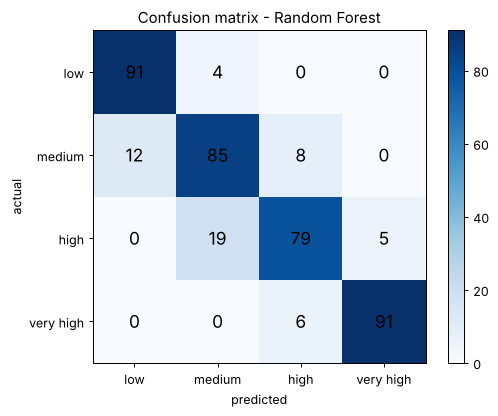

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm, cmap="Blues")
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xticks([0, 1, 2, 3], ["low", "medium", "high", "very high"])
plt.yticks([0, 1, 2, 3], ["low", "medium", "high", "very high"])
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix - Random Forest")
plt.colorbar()
plt.show()

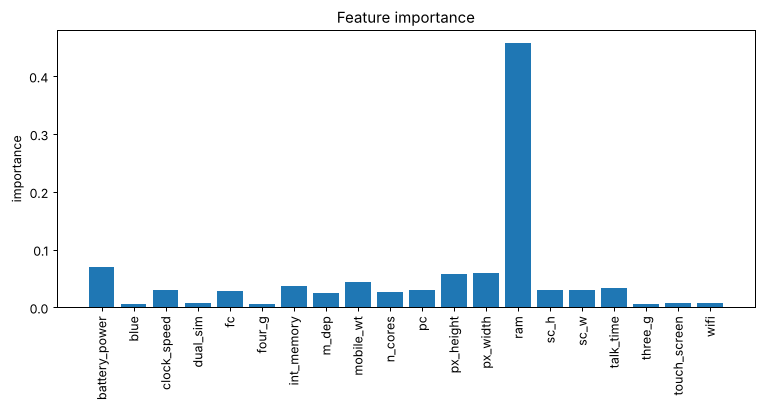

In [11]:
# which features are the most important for the forest
plt.figure(figsize=(10, 4))
plt.bar(feature_names, model.feature_importances_)
plt.xticks(rotation=90)
plt.ylabel("importance")
plt.title("Feature importance")
plt.show()

## Conclusion
Random Forest does not use gradient descent, so it has no learning rate or loss curve. It learns by splitting the data in the trees. The validation data was used to choose its settings.

The train accuracy is 100% but the validation accuracy is lower, so the forest overfits a little. RAM is by far the most important feature.